# 01 · Preprocesamiento

De la descarga cruda de ClickPy y GitHub (`data/raw/`) a las tablas limpias de `data/processed/`. Cada decisión va con su motivo; la lógica vive en `src/radar/preparacion.py` y este notebook la recorre con los datos reales.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from radar import preparacion as prep

plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.max_columns", 30)

## 1. Lo que llega de la ingesta

In [2]:
lanzamientos, repos, series = prep.cargar_raw()
existentes = sum(1 for r in repos.values() if r)
print(f"Paquetes nuevos en PyPI con un enlace a GitHub: {len(lanzamientos):,}")
print(f"Repositorios consultados: {len(repos):,} ({existentes:,} existen)")
print(
    f"Series diarias descargadas (repositorio con 10 estrellas o más): {len(series):,}"
)

Paquetes nuevos en PyPI con un enlace a GitHub: 79,193
Repositorios consultados: 69,131 (54,243 existen)
Series diarias descargadas (repositorio con 10 estrellas o más): 10,610


In [3]:
# Un lanzamiento tal como llega de ClickPy y una serie diaria: fecha → [de usuario, totales]
ejemplo = next(p for p in lanzamientos if p["paquete"] in series)
print(
    json.dumps(
        {
            k: ejemplo[k]
            for k in [
                "paquete",
                "primera_subida",
                "dependencias",
                "dias_subida",
                "versiones",
            ]
        },
        indent=1,
    )
)
dict(list(series[ejemplo["paquete"]]["dias"].items())[:5])

{
 "paquete": "aarya",
 "primera_subida": "2025-11-30 16:16:01.855",
 "dependencias": 5,
 "dias_subida": [
  "2025-11-30",
  "2025-12-05",
  "2026-01-30"
 ],
 "versiones": 9
}


{'2025-11-30': [29, 1068],
 '2025-12-01': [22, 233],
 '2025-12-02': [5, 46],
 '2025-12-03': [6, 56],
 '2025-12-04': [7, 27]}

**Conclusión.** ClickPy dio unos 79.000 paquetes publicados por primera vez en los doce meses de la ventana con algún enlace a github.com. De sus repositorios existe casi el 80 % (el resto se borró o se renombró), y solo 10.610 paquetes tienen un repositorio con 10 estrellas o más: son los candidatos, y de ellos se descargó la serie diaria del día −30 al 89.

## 2. Unión de fuentes y tipos

Cada paquete se une con su repositorio por la URL de GitHub de su ficha (`extraer_repo`) y con su serie diaria por el nombre normalizado (PEP 503). Cada día se sitúa respecto a la primera subida (día 0) y se acumulan las descargas hasta los días de lectura.

In [4]:
paquetes, diarias = prep.construir_tablas(lanzamientos, repos, series)
candidatos = paquetes[~paquetes["estado"].isin(["sin_repo", "pocas_estrellas"])]
print(
    candidatos[
        ["fecha_lanzamiento", "estrellas", "usuario_30d", "total_30d", "subidas_30d"]
    ].dtypes
)
candidatos[
    [
        "paquete",
        "repo",
        "categoria",
        "estrellas",
        "usuario_7d",
        "usuario_30d",
        "total_30d",
    ]
].head()

fecha_lanzamiento     object
estrellas            float64
usuario_30d          float64
total_30d            float64
subidas_30d            int64
dtype: object


,paquete,repo,categoria,estrellas,usuario_7d,usuario_30d,total_30d
10,115cli,xavier-lam/115cli,Web y APIs,14.0,21.0,89.0,2613.0
11,1200km-aidebug,anpa1200/aidebug,Machine learning,16.0,44.0,60.0,1904.0
30,3brown1blue,amitsubhash/3brown1blue,Agentes y LLM,51.0,141.0,196.0,5600.0
31,3dcitydb-mcp-server,tum-gis/3dcitydb-mcp-server,Agentes y LLM,23.0,24.0,215.0,2513.0
33,3dsmax-mcp,cl0nazepamm/3dsmax-mcp,Agentes y LLM,402.0,107.0,258.0,1472.0


**Conclusión.** Fechas como fecha, conteos enteros y una categoría por paquete. Las descargas llegan separadas en dos: «de usuario» (pip, uv, poetry, pdm, pipenv y pex) y totales (además mirrors, navegadores y peticiones sin instalador). Esa separación es la decisión central del proyecto, y el EDA (P1) explica por qué.

## 3. Nulos y duplicados

In [5]:
print("Paquetes duplicados:", candidatos["paquete"].duplicated().sum())
print("Nulos en los candidatos:")
candidatos[
    ["repo", "estrellas", "usuario_30d", "anios_cuenta", "dias_repo_previos"]
].isna().sum()

Paquetes duplicados: 0
Nulos en los candidatos:


repo                 0
estrellas            0
usuario_30d          0
anios_cuenta         0
dias_repo_previos    0
dtype: int64

In [6]:
# Varios paquetes del mismo repositorio (monorepos, plugins) comparten estrellas
aptos = paquetes[paquetes["estado"] == "apto"]
por_repo = aptos.groupby("repo").size()
print(
    f"Repositorios con más de un paquete apto: {(por_repo > 1).sum()} ({aptos['repo_compartido'].sum()} paquetes)"
)
por_repo.nlargest(5)

Repositorios con más de un paquete apto: 403 (1469 paquetes)


repo
airbytehq/airbyte-agent-sdk           52
jinning6/noosphere                    41
vectorize-io/hindsight                33
microsoft/agent-governance-toolkit    32
vaquarkhan/mcp-test-harness           26
dtype: int64

**Conclusión.** No hay paquetes duplicados: un mismo mes puede aparecer en dos ficheros si la ventana se mueve, y la preparación se queda con la primera aparición. Los nulos están donde deben (sin repositorio o sin serie, que se excluyen después). Hay repositorios con varios paquetes (monorepos como los SDK de un mismo proveedor): sirven para el radar, que mide cada paquete, pero no para el contraste con estrellas, que se hace con un paquete por repositorio.

## 4. Descargas antes del día 0

Si un paquete tiene descargas antes de su primera subida, tuvo versiones que luego se borraron de PyPI: su día 0 no es el estreno real.

Con alguna descarga antes del día −1: 542
Con más del 5 % del primer mes: 486


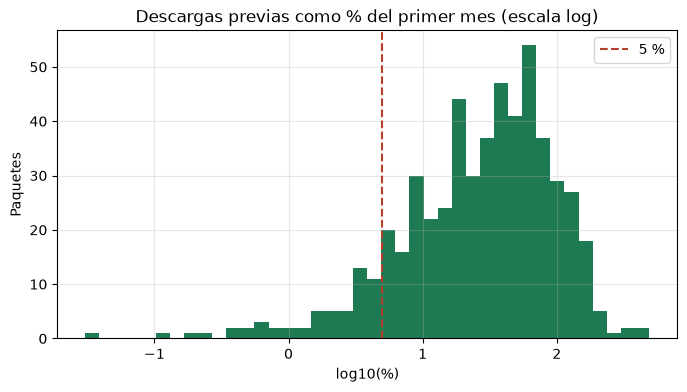

In [7]:
previas = candidatos["pct_previas"]
print(f"Con alguna descarga antes del día −1: {(previas > 0).sum()}")
print(f"Con más del 5 % del primer mes: {(previas > prep.PCT_PREVIAS_MAX).sum()}")
fig, ax = plt.subplots()
ax.hist(np.log10(previas[previas > 0] * 100), bins=40, color="#1e7a52")
ax.axvline(np.log10(5), color="#b3402a", ls="--", label="5 %")
ax.set(
    title="Descargas previas como % del primer mes (escala log)",
    xlabel="log10(%)",
    ylabel="Paquetes",
)
ax.legend();

**Conclusión.** Unos 540 candidatos tienen descargas anteriores a su primera subida y casi todos superan el 5 %: no es ruido de un día, son paquetes con un historial borrado. Se excluyen con el umbral del 5 %.

## 5. ¿Es un lanzamiento?

El radar es para proyectos nuevos. Dos casos se parecen a un lanzamiento en PyPI sin serlo: proyectos que ya existían en GitHub y empiezan a publicar (o cambian de nombre), y copias de proyectos ajenos.

0.25       8.0
0.50     246.0
0.75    1397.0
Name: dias_repo_previos, dtype: float64

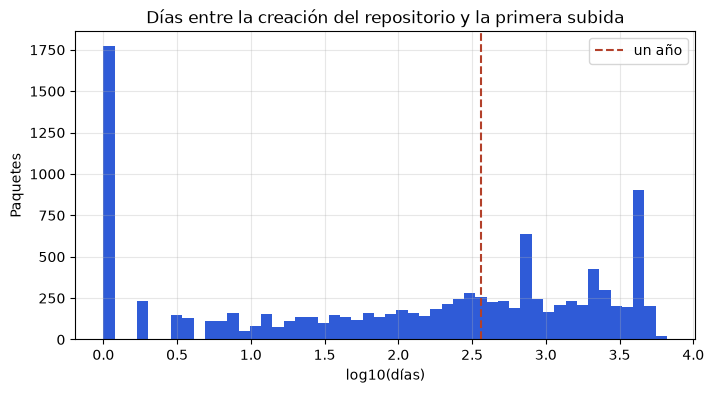

In [8]:
fig, ax = plt.subplots()
dias = candidatos["dias_repo_previos"].clip(lower=1)
ax.hist(np.log10(dias), bins=50, color="#2f5bd7")
ax.axvline(
    np.log10(prep.DIAS_REPO_PREVIOS_MAX), color="#b3402a", ls="--", label="un año"
)
ax.set(
    title="Días entre la creación del repositorio y la primera subida",
    xlabel="log10(días)",
    ylabel="Paquetes",
)
ax.legend()
candidatos["dias_repo_previos"].quantile([0.25, 0.5, 0.75]).round()

In [9]:
# Prefijos que alguien pone delante del nombre de repositorios de muchos dueños distintos
ajenos = prep.republicadores(candidatos)
print("Republicadores detectados:", ajenos)
candidatos[candidatos["estado"] == "republicado"][
    ["paquete", "repo", "estrellas", "usuario_30d"]
].head(6)

Republicadores detectados: {'mseep', 'iflow-mcp'}


,paquete,repo,estrellas,usuario_30d
30913,iflow-mcp-0xhackerfren-frida-game-hacking-mcp,0xhackerfren/frida-game-hacking-mcp,92.0,14.0
30914,iflow-mcp-1405942836-appium-mcp-server,1405942836/appium-mcp,42.0,9.0
30916,iflow-mcp-2niuhe-mcp-plantuml,2niuhe/mcp_plantuml,15.0,18.0
30917,iflow-mcp-4r9un-fastmcp-threatintel,4r9un/fastmcp-threatintel,40.0,22.0
30918,iflow-mcp-4r9un-mcp-kql-server,4r9un/mcp-kql-server,24.0,8.0
30919,iflow-mcp-54yyyu-pyapple-mcp,54yyyu/pyapple-mcp,17.0,18.0


**Conclusión.** La mitad de los candidatos tiene un repositorio de más de 8 meses cuando sube a PyPI, y una cuarta parte de más de tres años: son proyectos con usuarios previos. Se excluyen los de más de un año (4.449). Además aparecen dos republicadores masivos, `iflow-mcp-…` y `mseep-…`, que suben a PyPI cientos de servidores MCP de otros y enlazan el repositorio original, quedándose con sus estrellas: 385 paquetes fuera. La regla no usa una lista escrita a mano: un prefijo cuenta si lo usan paquetes de repositorios de al menos 10 dueños distintos y si al menos la mitad de sus paquetes siguen ese patrón. La segunda condición importa: sin ella, ecosistemas de plugins como `langchain-…` o `django-…` también caerían, y ahí el patrón no pasa del 20 %.

## 6. Exclusiones

In [10]:
pd.Series(prep.embudo(paquetes)).to_frame("paquetes que quedan")

,paquetes que quedan
con_enlace_a_github,79193
tras_sin_repo,61817
tras_pocas_estrellas,10610
tras_republicado,10225
tras_repo_fork,10147
tras_sin_descargas,10147
tras_mes_incompleto,10147
tras_versiones_previas_borradas,9666
tras_proyecto_anterior,5217


**Conclusión.** De unos 79.000 paquetes nuevos con enlace a GitHub quedan 5.217 aptos. Casi todo el recorte viene de los dos primeros filtros (repositorio que exista y con al menos 10 estrellas), que separan los proyectos que alguien sigue de las pruebas, plantillas y paquetes abandonados que se suben cada día.

## 7. Valores atípicos

El volumen tiene una cola muy larga. Se mira en escala logarítmica para decidir si hay errores o solo paquetes muy grandes.

count        5217.0
mean        16976.0
std        703111.0
min             0.0
50%            93.0
90%           923.0
99%         21915.0
max      48753650.0
Name: usuario_30d, dtype: float64

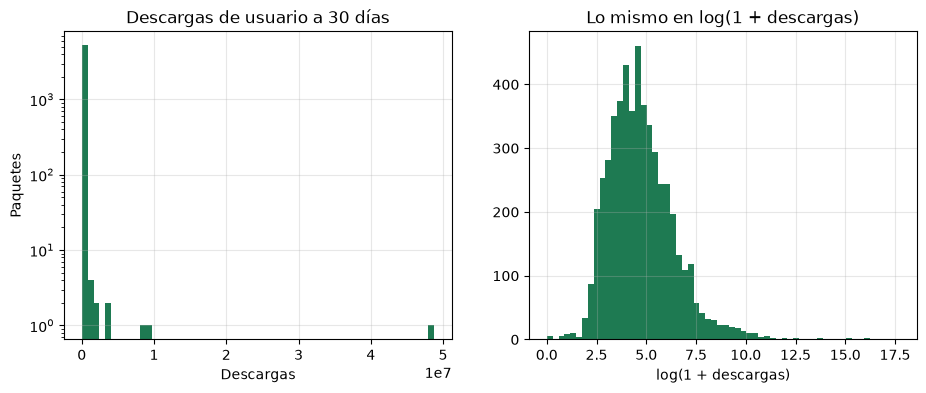

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(aptos["usuario_30d"], bins=60, color="#1e7a52")
axes[0].set(
    title="Descargas de usuario a 30 días",
    xlabel="Descargas",
    ylabel="Paquetes",
    yscale="log",
)
axes[1].hist(np.log1p(aptos["usuario_30d"]), bins=60, color="#1e7a52")
axes[1].set(title="Lo mismo en log(1 + descargas)", xlabel="log(1 + descargas)")
aptos["usuario_30d"].describe(percentiles=[0.5, 0.9, 0.99]).round()

In [12]:
aptos.nlargest(5, "usuario_30d")[
    ["paquete", "repo", "estrellas", "usuario_30d", "total_30d"]
]

,paquete,repo,estrellas,usuario_30d,total_30d
73853,uncalled-for,chrisguidry/uncalled-for,17.0,48753650.0,48794784.0
30156,httpcore2,pydantic/httpx2,1676.0,8994550.0,9005886.0
30177,httpx2,pydantic/httpx2,1676.0,8886561.0,8898253.0
16617,daytona-analytics-api-client,daytona/clients,17.0,3818075.0,3824039.0
16618,daytona-analytics-api-client-async,daytona/clients,17.0,3798985.0,3804863.0


**Conclusión.** La distribución es muy asimétrica: mediana de 93 descargas de usuario en el primer mes, media de unas 17.000 y un 1 % por encima de 21.900. Los más grandes no son errores: son dependencias que otro paquete muy usado arrastra (`uncalled-for`, `httpx2` y `httpcore2`, clientes generados de un SDK), con millones de instalaciones y pocas estrellas. No se recortan; el modelo trabaja en log(1 + descargas).

## 8. Tabla final

In [13]:
dataset = prep.dataset_radar(paquetes)
print(dataset.shape)
print("Nulos:", dataset.isna().sum().sum())
dataset.head()

(5217, 24)
Nulos: 0


,paquete,nombre,repo,fecha_lanzamiento,categoria,propietario_tipo,dependencias,dias_repo_previos,anios_cuenta,mes_lanzamiento,usuario_7d,total_7d,subidas_7d,usuario_14d,total_14d,subidas_14d,usuario_21d,total_21d,subidas_21d,usuario_30d,total_30d,subidas_30d,estrellas,repo_compartido
0,falkordb-orm,falkordb-orm,falkordb/falkordb-py-orm,2025-11-23,Datos y ciencia,Organización,2,0.0,2.35,11,68.0,1300.0,2,81.0,1980.0,3,83.0,2190.0,3,85.0,2292.0,3,11.0,False
1,kimina-ast-server,kimina-ast-server,project-numina/kimina-lean-server,2025-11-23,Web y APIs,Organización,10,214.0,1.85,11,67.0,892.0,2,69.0,1003.0,2,76.0,1315.0,3,82.0,1515.0,3,217.0,False
2,ufazien-cli,ufazien-cli,martian56/ufazien-cli,2025-11-23,Web y APIs,Persona,3,3.0,2.03,11,42.0,550.0,2,59.0,898.0,3,59.0,982.0,3,59.0,1047.0,3,49.0,False
3,oicana-native,oicana-native,oicana/oicana,2025-11-23,Herramientas de desarrollo,Organización,0,74.0,1.11,11,103.0,781.0,1,116.0,1317.0,2,121.0,1498.0,2,121.0,1587.0,2,37.0,True
4,zon-format,zon-format,zon-format/zon,2025-11-23,Agentes y LLM,Organización,0,0.0,0.00,11,53.0,1081.0,3,104.0,1857.0,5,219.0,2444.0,6,308.0,2677.0,6,72.0,False


In [14]:
# Mismas salidas que `python -m radar.preparacion`
prep.main();

INFO 10610 paquetes, 5217 aptos. Exclusiones: {'apto': 5217, 'proyecto_anterior': 4449, 'versiones_previas_borradas': 481, 'republicado': 385, 'repo_fork': 78}


**Conclusión.** Una fila por paquete apto con las lecturas a 7, 14 y 21 días (descargas de usuario, totales y días con subidas), el objetivo a 30 días y las variables previas al lanzamiento (categoría, tipo de propietario, dependencias, antigüedad de la cuenta y del repositorio, mes). Las estrellas van aparte: son las de hoy y solo sirven de contraste.